# 5. Тип происшествия (Event): как люди травмируются

Данные: `OSHA_db`, 105 996 тяжёлых травм (январь 2015 – ноябрь 2025). SQL-запросы — `SQL/05_events.sql`.

Коды OIICS иерархические: первая цифра — раздел (4 — падения, 6 — контакт с предметами и оборудованием …). Одинаковые названия под разными кодами объединены.

Что добавляет Python: тяжесть по разделам с 95% ДИ, связь типа происшествия с частью тела (χ², V Крамера), доли разделов по годам с учётом смены классификации.

In [1]:
import os
if not os.path.isdir("src"):  # ноутбук запущен из notebooks/, а не из Analysis/
    os.chdir("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from scipy import stats

from src.db import query
from src.viz import set_style, tr, finish, barh_ranked, wrap, LANGS, TABLES_DIR, MAIN, ACCENT, SERIES
from src.stats import num, cramers_v, share_ci, rank_by_title
from src.labels import norm_title, event_ru, EVENT_DIVISIONS, BODY_DIVISIONS

set_style()
TABLES_DIR.mkdir(exist_ok=True)

## 5.0. Исходные данные

In [2]:
cases = query("""
    SELECT i.id,
           EXTRACT(YEAR FROM i.event_date)::int AS year,
           i.event_code,
           e.title                              AS event,
           i.part_of_body_code,
           i.severity_code
    FROM injuries i
    JOIN event_lookup e ON e.code = i.event_code
""")
cases["event_div"] = cases["event_code"].astype(str).str[0]
cases["body_div"] = cases["part_of_body_code"].astype(str).str[0]
cases["hospitalization"] = (cases["severity_code"] & 4) > 0
cases["amputation"] = (cases["severity_code"] & 2) > 0
N = len(cases)
print(f"Случаев: {num(N)}")

Случаев: 105 996


## 5.1. Разделы типов происшествий и тяжесть

In [3]:
rows = []
for d, g in cases.groupby("event_div"):
    a, a_lo, a_hi = share_ci(g["amputation"].sum(), len(g))
    h, h_lo, h_hi = share_ci(g["hospitalization"].sum(), len(g))
    rows.append({"division": d, "name_ru": EVENT_DIVISIONS[d][0], "name_en": EVENT_DIVISIONS[d][1],
                 "cases": len(g), "pct_of_all": 100 * len(g) / N,
                 "pct_hospitalized": h, "hosp_ci_low": h_lo, "hosp_ci_high": h_hi,
                 "pct_amputation": a, "amp_ci_low": a_lo, "amp_ci_high": a_hi})
div = pd.DataFrame(rows).sort_values("cases", ascending=False).reset_index(drop=True)
div.round(2).to_csv(TABLES_DIR / "05_1_event_divisions.csv", index=False, encoding="utf-8-sig")

chi2, p, dof, v, _ = cramers_v(pd.crosstab(cases["event_div"], cases["amputation"]))
print(f"Раздел происшествия × ампутация: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")
div[["name_ru", "cases", "pct_of_all", "pct_hospitalized", "pct_amputation"]].round(2)

Раздел происшествия × ампутация: χ² = 36 667, df = 7, p = 0.00e+00, V Крамера = 0.588


,name_ru,cases,pct_of_all,pct_hospitalized,pct_amputation
0,Контакт с предметами и оборудованием,48445,45.70,60.12,54.46
1,"Падения, поскальзывания, спотыкания",32713,30.86,99.26,1.13
2,Транспортные происшествия,9402,8.87,95.75,8.87
3,Воздействие вредных веществ и среды,8691,8.20,99.91,0.52
4,"Насилие, травмы от людей и животных",2343,2.21,97.40,3.84
5,Пожары и взрывы,1864,1.76,99.57,1.98
6,Перенапряжение и реакция организма,1709,1.61,100.00,0.23
7,Не классифицировано,829,0.78,85.89,23.88


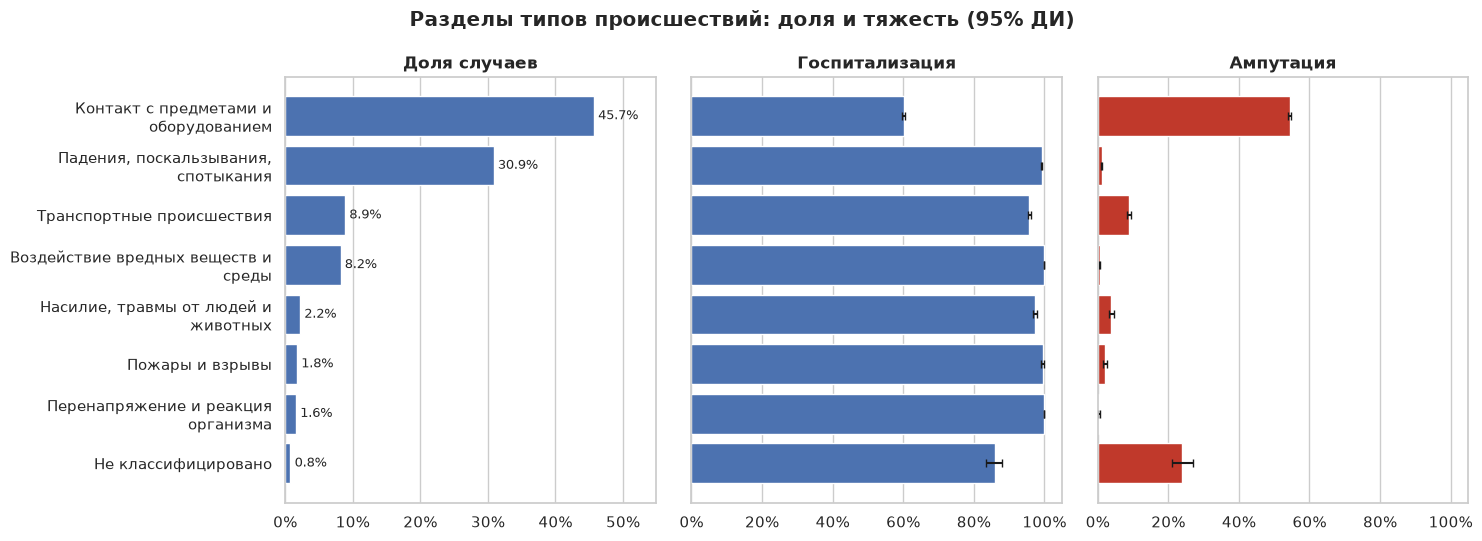

In [4]:
for lang in LANGS:
    names = [wrap(n, 32) for n in (div["name_ru"] if lang == "ru" else div["name_en"])]
    y = np.arange(len(div))[::-1]
    fig, axes = plt.subplots(1, 3, figsize=(15, 5.5), sharey=True)
    b = axes[0].barh(y, div["pct_of_all"], color=MAIN)
    axes[0].bar_label(b, labels=[f"{p:.1f}%" for p in div["pct_of_all"]], padding=3, fontsize=9)
    axes[0].set_title(tr("Доля случаев", "Share of cases", lang))
    axes[0].set_xlim(0, div["pct_of_all"].max() * 1.2)
    for ax, col, color, t in [(axes[1], "hosp", MAIN, ("Госпитализация", "Hospitalization")),
                              (axes[2], "amp", ACCENT, ("Ампутация", "Amputation"))]:
        pc = div["pct_hospitalized" if col == "hosp" else "pct_amputation"]
        ax.barh(y, pc, color=color, xerr=[pc - div[f"{col}_ci_low"], div[f"{col}_ci_high"] - pc], capsize=3)
        ax.set_title(tr(*t, lang))
        ax.set_xlim(0, 105)
    for ax in axes:
        ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, names)
    fig.suptitle(tr("Разделы типов происшествий: доля и тяжесть (95% ДИ)",
                    "Event divisions: share and severity (95% CI)", lang), fontweight="bold")
    fig.tight_layout()
    finish(fig, "05_1_event_divisions", lang)

## 5.2. Топ-15 конкретных типов происшествий

Подпись у столбца — доля от всех случаев и доля ампутаций среди случаев этого типа.

In [5]:
top = rank_by_title(cases["event"], cases["event_code"])
amp = cases.assign(key=cases["event"].map(norm_title)).groupby("key")["amputation"].mean() * 100
top["pct_amputation"] = amp.reindex(top.index)
top["event_ru"] = top["title"].map(event_ru)
top = top.reset_index(drop=True)[["title", "event_ru", "codes", "cases", "pct", "pct_amputation"]]
top.index += 1
top.head(20).round(2).to_csv(TABLES_DIR / "05_2_top_events.csv", encoding="utf-8-sig")
top.head(20).round(2)

,title,event_ru,codes,cases,pct,pct_amputation
1,"Other fall to lower level, unspecified",Падение с высоты (не уточнено),"4140, 4330",6934,6.54,0.65
2,Caught in running equipment or machinery durin...,Затянуло в работающее оборудование (штатная ра...,6412,6694,6.32,72.98
3,Caught in running equipment or machinery durin...,"Затянуло в оборудование при обслуживании, чистке",6411,5298,5.00,72.40
4,Compressed or pinched by shifting objects or e...,"Сдавило смещающимися предметами, оборудованием",642,4985,4.70,75.63
5,Other fall to lower level less than 6 feet,"Падение с высоты менее 1,8 м","4141, 4331",4009,3.78,0.52
6,Fall on same level due to slipping,Падение на одном уровне: поскользнулся,422,3681,3.47,1.33
7,Fall on same level due to tripping over an object,Падение на одном уровне: споткнулся о предмет,4213,2660,2.51,1.13
8,Struck against moving part of machinery or equ...,Удар о движущуюся часть машины,6311,2235,2.11,81.52
9,Caught in or compressed by equipment or object...,Захват или сдавливание оборудованием (не уточн...,640,2221,2.10,71.63
10,Exposure to environmental heat,Воздействие жары окружающей среды,531,2196,2.07,0.05


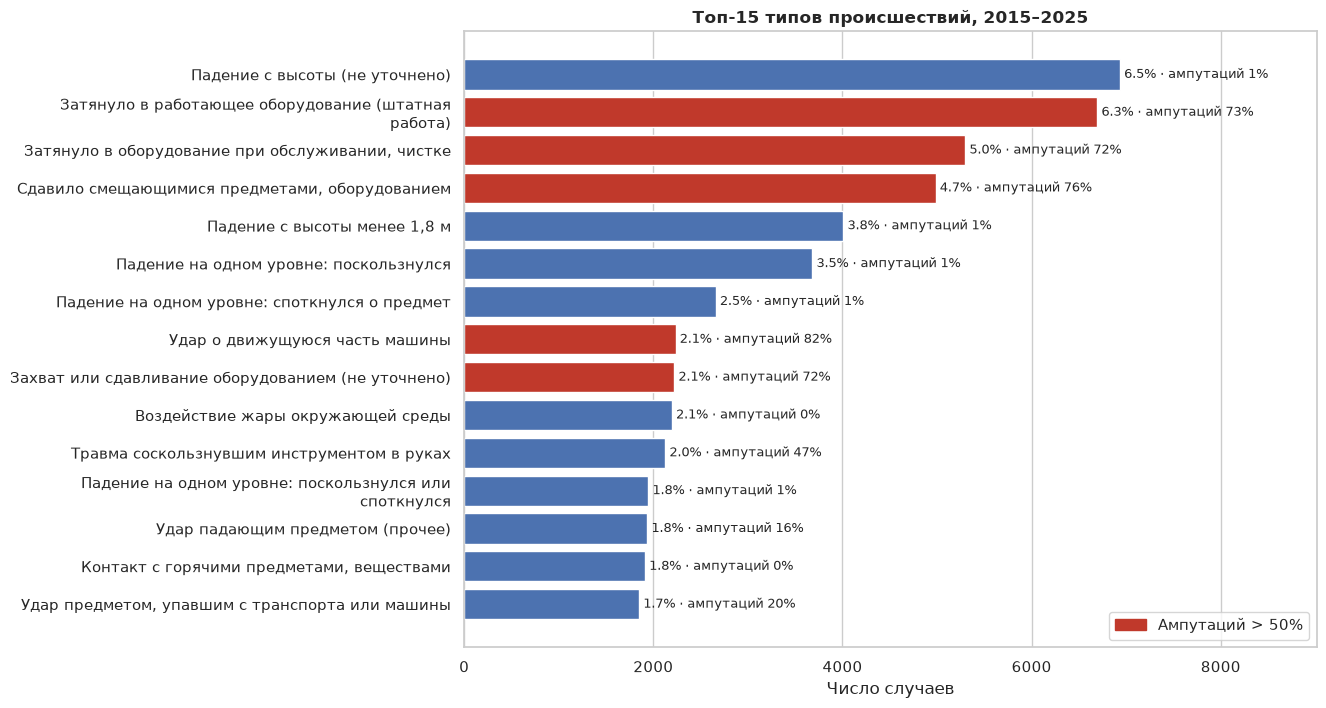

In [6]:
t = top.head(15)
for lang in LANGS:
    fig, ax = plt.subplots(figsize=(11, 8))
    notes = [tr(f"{p:.1f}% · ампутаций {a:.0f}%", f"{p:.1f}% · amputations {a:.0f}%", lang)
             for p, a in zip(t["pct"], t["pct_amputation"])]
    barh_ranked(ax, t["event_ru"] if lang == "ru" else t["title"], t["cases"], notes=notes,
                color=np.where(t["pct_amputation"] > 50, ACCENT, MAIN), width=50)
    ax.margins(x=0.3)
    ax.set_title(tr("Топ-15 типов происшествий, 2015–2025", "Top 15 event types, 2015–2025", lang))
    ax.set_xlabel(tr("Число случаев", "Number of cases", lang))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ACCENT)],
              labels=[tr("Ампутаций > 50%", "Amputations > 50%", lang)], loc="lower right")
    finish(fig, "05_2_top_events", lang)

## 5.3. Тип происшествия × раздел тела

SQL 5.3 — абсолютные числа. Здесь — проценты по строке (куда приходится травма при данном типе происшествия) и сила связи.

Раздел происшествия × раздел тела: χ² = 95 302, df = 49, p = 0.00e+00, V Крамера = 0.358


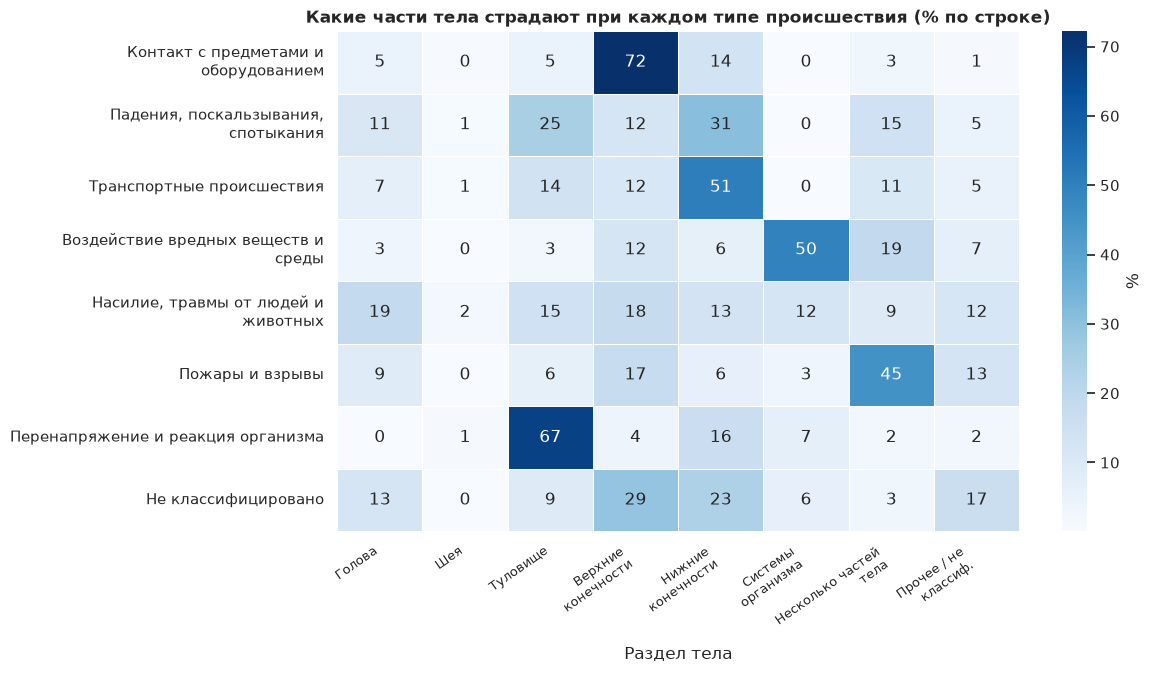

In [7]:
order = div["division"].tolist()
ct = pd.crosstab(cases["event_div"], cases["body_div"]).loc[order]
chi2, p, dof, v, _ = cramers_v(ct)
print(f"Раздел происшествия × раздел тела: χ² = {num(chi2)}, df = {dof}, p = {p:.2e}, V Крамера = {v:.3f}")
row_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct.to_csv(TABLES_DIR / "05_3_event_body_counts.csv", encoding="utf-8-sig")
row_pct.round(1).to_csv(TABLES_DIR / "05_3_event_body_row_pct.csv", encoding="utf-8-sig")

for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(11, 6.5))
    sns.heatmap(row_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "%"},
                linewidths=0.5, linecolor="white", ax=ax,
                xticklabels=[wrap(BODY_DIVISIONS[d][k], 16) for d in row_pct.columns],
                yticklabels=[wrap(EVENT_DIVISIONS[d][k], 34) for d in row_pct.index])
    ax.set_title(tr("Какие части тела страдают при каждом типе происшествия (% по строке)",
                    "Body divisions affected by each event division (row %)", lang))
    ax.set_xlabel(tr("Раздел тела", "Body division", lang))
    ax.set_ylabel("")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", fontsize=9)
    finish(fig, "05_3_event_body_heatmap", lang)

## 5.4. Разделы типов происшествий по годам

С 2024 года действует новая редакция OIICS: резко падают доли «Насилие» и «Не классифицировано» — это эффект кодирования, а не реальное изменение. Тренды считаются по сопоставимому периоду 2016–2023 (2015 год также выбивается по «не классифицировано», см. раздел 1).

In [8]:
by_year = pd.crosstab(cases["year"], cases["event_div"], normalize="index")[order] * 100
by_year.round(2).to_csv(TABLES_DIR / "05_4_event_divisions_by_year.csv", encoding="utf-8-sig")
comparable = by_year.loc[2016:2023]
for d in order:
    lr = stats.linregress(comparable.index, comparable[d])
    print(f"{EVENT_DIVISIONS[d][0]:<38} наклон {lr.slope:+.2f} п.п. в год, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3f}")
by_year.set_axis([EVENT_DIVISIONS[d][0] for d in order], axis=1).round(1)

Контакт с предметами и оборудованием   наклон -0.33 п.п. в год, R² = 0.70, p = 0.010
Падения, поскальзывания, спотыкания    наклон +0.21 п.п. в год, R² = 0.67, p = 0.013
Транспортные происшествия              наклон +0.28 п.п. в год, R² = 0.73, p = 0.007
Воздействие вредных веществ и среды    наклон -0.14 п.п. в год, R² = 0.20, p = 0.263
Насилие, травмы от людей и животных    наклон +0.08 п.п. в год, R² = 0.57, p = 0.031
Пожары и взрывы                        наклон -0.00 п.п. в год, R² = 0.00, p = 0.937
Перенапряжение и реакция организма     наклон -0.05 п.п. в год, R² = 0.41, p = 0.088
Не классифицировано                    наклон -0.04 п.п. в год, R² = 0.39, p = 0.098


,Контакт с предметами и оборудованием,"Падения, поскальзывания, спотыкания",Транспортные происшествия,Воздействие вредных веществ и среды,"Насилие, травмы от людей и животных",Пожары и взрывы,Перенапряжение и реакция организма,Не классифицировано
year,,,,,,,,
2015,47.5,29.6,7.6,8.0,1.9,1.6,2.0,1.8
2016,46.8,29.6,7.9,9.5,2.2,1.6,1.6,0.8
2017,46.9,30.3,8.0,7.9,2.4,1.8,1.8,1.0
2018,45.8,30.1,8.7,8.4,2.3,1.9,1.7,1.0
2019,45.3,30.4,8.7,8.9,2.3,2.0,1.8,0.6
2020,45.5,31.3,9.6,7.3,2.5,1.5,1.6,0.7
2021,45.1,31.2,9.8,7.3,2.8,1.6,1.3,0.8
2022,43.9,31.3,9.9,7.9,2.9,1.7,1.6,0.7
2023,45.3,30.8,9.2,8.5,2.5,1.8,1.3,0.6


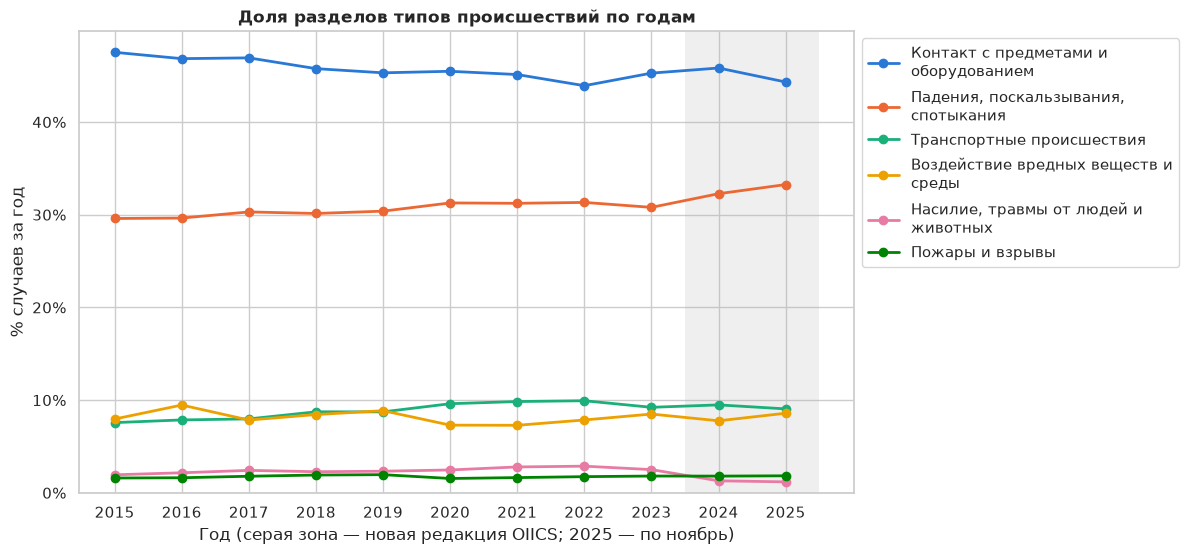

In [9]:
main = order[:6]
for lang in LANGS:
    k = 0 if lang == "ru" else 1
    fig, ax = plt.subplots(figsize=(10, 6))
    for d, color in zip(main, SERIES):
        ax.plot(by_year.index, by_year[d], marker="o", color=color, lw=2, label=wrap(EVENT_DIVISIONS[d][k], 32))
    ax.axvspan(2023.5, 2025.5, color="#b0b0b0", alpha=0.2, lw=0)
    ax.set_title(tr("Доля разделов типов происшествий по годам", "Share of event divisions by year", lang))
    ax.set_xlabel(tr("Год (серая зона — новая редакция OIICS; 2025 — по ноябрь)",
                     "Year (grey — new OIICS edition; 2025 — through November)", lang))
    ax.set_ylabel(tr("% случаев за год", "% of cases in year", lang))
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xticks(by_year.index)
    ax.set_ylim(0, None)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    finish(fig, "05_4_event_divisions_by_year", lang)

## Выводы

1. **Два раздела дают 77% тяжёлых травм:** контакт с предметами и оборудованием (45,7%) и падения, поскальзывания, спотыкания (30,9%). Далее транспортные происшествия (8,9%) и воздействие вредных веществ и среды (8,2%).
2. **Контакт с оборудованием — главный источник ампутаций** (54,5% таких случаев заканчиваются ампутацией; χ² по разделам = 36 667, V Крамера = 0,59 — сильная связь). Самые опасные типы: удар о движущуюся часть машины (82% ампутаций), сдавливание смещающимися предметами (76%), затягивание в оборудование при штатной работе и при обслуживании/чистке (по 72–73%). Падения почти никогда не приводят к ампутации (1,1%), но в 99% случаев — госпитализация.
3. **Самый частый конкретный тип** — падение с высоты без уточнения (6,5%), за ним затягивание в работающее оборудование (6,3%) и при обслуживании (5,0%). Треть случаев затягивания происходит во время обслуживания и чистки — это прямой аргумент за блокировку оборудования (lockout/tagout).
4. **Тип происшествия определяет часть тела** (V Крамера = 0,36): при контакте с оборудованием 72% травм — верхние конечности; при падениях и транспортных происшествиях — нижние конечности (31% и 51%); при перенапряжении — туловище (67%); при воздействии среды — системы организма (50%).
5. **Динамика (2016–2023, сопоставимая классификация):** доля контакта с оборудованием снижается (−0,33 п.п. в год, p = 0,01), доли падений (+0,21) и транспортных происшествий (+0,28 п.п. в год) растут. Резкое падение «насилия» и «не классифицировано» в 2024–2025 годах — эффект новой редакции OIICS.